In [1]:
import pandas as pd
import numpy as np
import copepodTCR as cpp
import seaborn as sn
from matplotlib import pyplot as plt

## plotting styles
plt.style.use('default')
color_basic = '#FFA500'
color_copepodTCR = '#015396'

## formula to calculate sensitivity and specificity based on the number of true-false positive-negatives
def calculate_tpr_fpr(tp, tn, fp, fn):

    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)

    return tpr, 1 - fpr

# copepodTCR outperforms existing CPP schemes in all tested edge-case scenarios.

In [2]:
# Methods comparison data

## DATA: simulations with negative share spanning 0.2-0.9
results = pd.read_csv('./data/insilico-simulations_methods-comparison.tsv', sep='\t')

## calculating sensitivity and specificity
tpr, fpr = calculate_tpr_fpr(results['TruePositive'], results['TrueNegative'], results['FalsePositive'], results['FalseNegative'])
results['Sensitivity'] = tpr
results['Specificity'] = fpr

## control == 0 activated pools
control = results[results['error'] == 100]
## with simulated 1 error
table_error = results[results['error'] == 1]
## with simulated 0 errors
table_noerror = results[results['error'] == 0]

/var/folders/bb/6j1bt4dj4x15t9jtm7vlh6gh0000gp/T/ipykernel_37332/2890532818.py:4: DtypeWarning: Columns (18,49) have mixed types. Specify dtype option on import or set low_memory=False.
  results = pd.read_csv('../data/insilico-simulations_methods-comparison.tsv', sep='\t')


In [3]:
# Cross-reactivity scenario

results_cross = pd.read_csv('./data/insilico-simulations_methods-comparison_crossreactivity.tsv', sep = '\t')

## calculating sensitivity and specificity
tpr_strong, fpr_strong = calculate_tpr_fpr(results_cross['TruePositive_strong'], results_cross['TrueNegative_strong'], results_cross['FalsePositive_strong'], results_cross['FalseNegative_strong'])
results_cross['Sensitivity_strong'] = tpr_strong
results_cross['Specificity_strong'] = fpr_strong

tpr_weak, fpr_weak = calculate_tpr_fpr(results_cross['TruePositive_weak'], results_cross['TrueNegative_weak'], results_cross['FalsePositive_weak'], results_cross['FalseNegative_weak'])
results_cross['Sensitivity_weak'] = tpr_weak
results_cross['Specificity_weak'] = fpr_weak

## A
 Performance of the interpretation
framework in the absence of signal, tested with two different background noise levels, here modeled as the wideness of
the negative distribution encoded by the mu_neg parameter in the simulation.

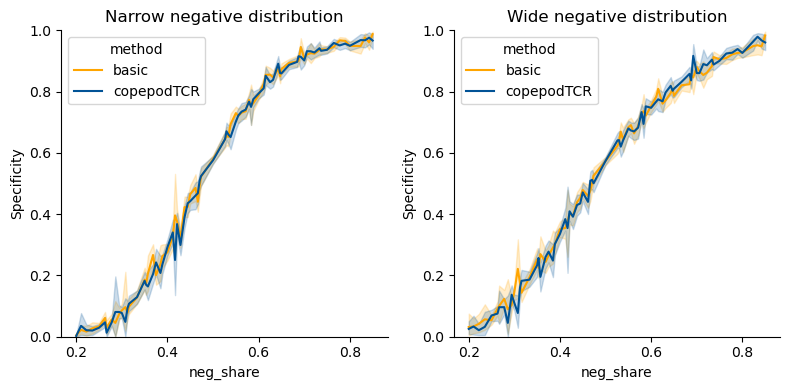

In [4]:
fig, axes = plt.subplots(1, 2, figsize = (8, 4))

## low noise (=> narrow negative distribution)
ax = axes[0]
sn.lineplot(control[control['sigma_neg'] == 5], y = 'Specificity', x = 'neg_share', hue = 'method',
            palette = [color_basic, color_copepodTCR], ax = ax)
ax.set_ylim(0, 1)
ax.set_title('Narrow negative distribution')

## high noise (=> wide negative distribution)
ax = axes[1]
sn.lineplot(control[control['sigma_neg'] == 20], y = 'Specificity', x = 'neg_share', hue = 'method',
            palette = [color_basic, color_copepodTCR], ax = ax)
ax.set_ylim(0, 1)
ax.set_title('Wide negative distribution')

sn.despine()
plt.tight_layout()

## B
Performance of the interpretation
framework tested with two different TCR affinities, here modeled as signal intensity encoded by the mu_signal parameter
in the simulation, which can be interpreted as the mean percentage of activated T cells per well.

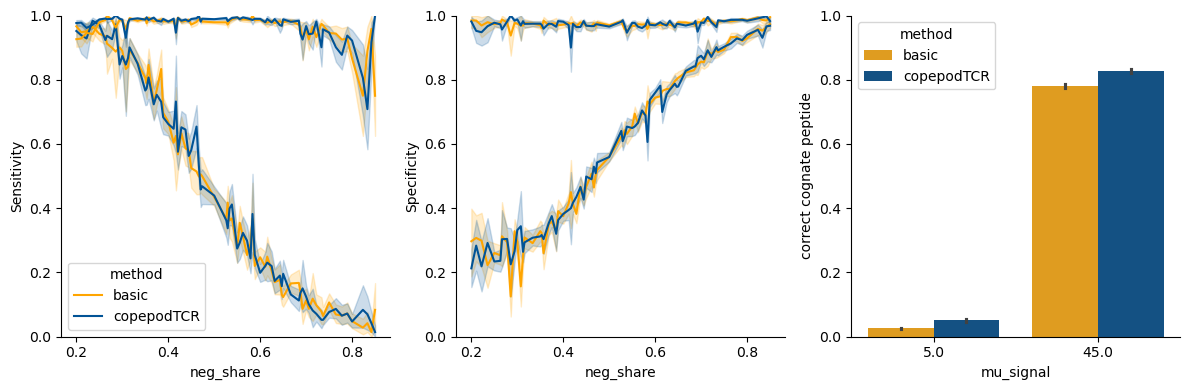

In [5]:
fig, axes = plt.subplots(1, 3, figsize = (12, 4))

for mu in [5, 45]:
    ## selecting a subset with needed signal intensity (low = 5, high = 45)
    subset = table_noerror[table_noerror['mu_signal'] == mu]

    ## sensitivity
    ax = axes[0]
    sn.lineplot(subset, x = 'neg_share', y = 'Sensitivity', hue = 'method',
                palette = [color_basic, color_copepodTCR], legend = (mu == 45), ax = ax)
    ax.set_ylim(0, 1)

    ## specificity
    ax = axes[1]
    sn.lineplot(subset, x = 'neg_share', y = 'Specificity', hue = 'method',
                palette = [color_basic, color_copepodTCR], legend=False, ax = ax)
    ax.set_ylim(0, 1)

## conclusion_cognate == True => list with correct cognate peptides == (exactly equal!) list of cognate peptides predicted by the model
ax = axes[2]
sn.barplot(table_noerror, x = 'mu_signal', y = 'conclusion_cognate', hue = 'method', ax = ax, palette = [color_basic, color_copepodTCR])
ax.set_ylabel('correct cognate peptide')
ax.set_ylim(0, 1)

plt.tight_layout()
sn.despine()

## C
Performance of
the interpretation framework tested with two different background noise levels, here modeled as the wideness of the
negative pool distributions encoded by the sigma_pools parameter in the simulation.

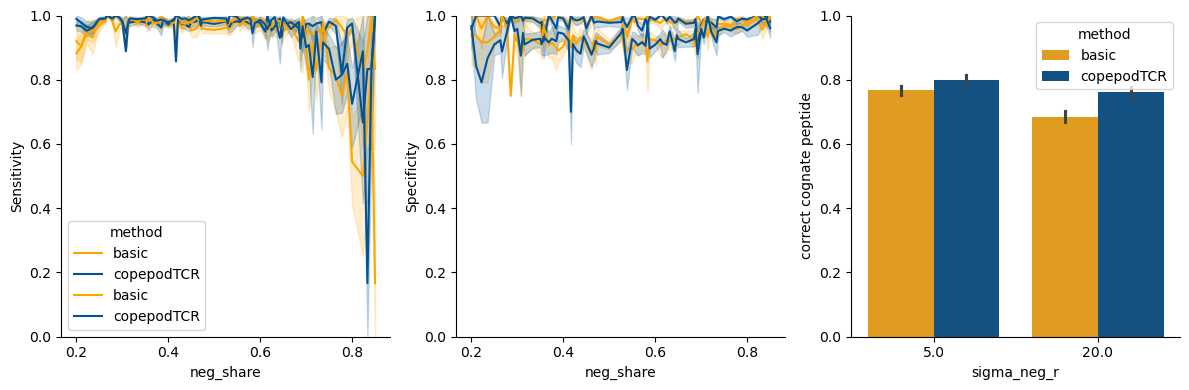

In [6]:
fig, axes = plt.subplots(1, 3, figsize = (12, 4))

## selecting a subset with high signal (mu_signal = 45) and wide negative distribution (sigma_neg = 20)
wide_neg = table_noerror[(table_noerror['sigma_neg'] == 20) & (table_noerror['mu_signal'] == 45)]

ax = axes[0]
for sigma in [5, 20]:
       ## selecting a subsubset with narrow and wide negative pools
       subset = wide_neg[wide_neg['sigma_neg_r'] == sigma]

       ## sensitivity
       ax = axes[0]
       sn.lineplot(subset, x = 'neg_share', y = 'Sensitivity', hue = 'method',
                palette = [color_basic, color_copepodTCR], legend = (mu == 45), ax = ax)
       ax.set_ylim(0, 1)

       ## specificity
       ax = axes[1]
       sn.lineplot(subset, x = 'neg_share', y = 'Specificity', hue = 'method',
                palette = [color_basic, color_copepodTCR], legend=False, ax = ax)
       ax.set_ylim(0, 1)

## conclusion_cognate == True => list with correct cognate peptides == (exactly equal!) list of cognate peptides predicted by the model
ax = axes[2]
sn.barplot(wide_neg, x = 'sigma_neg_r', y = 'conclusion_cognate', hue = 'method', ax = ax, palette = [color_basic, color_copepodTCR])
ax.set_ylim(0, 1)
ax.set_ylabel('correct cognate peptide')

plt.tight_layout()
sn.despine()

## D
 The performance of the proposed framework in the scenario
with two cognate peptides in the peptide library, one of which is a strong binder (modeled here as producing a high
activation signal), and the other is a weak binder (producing a weak signal).

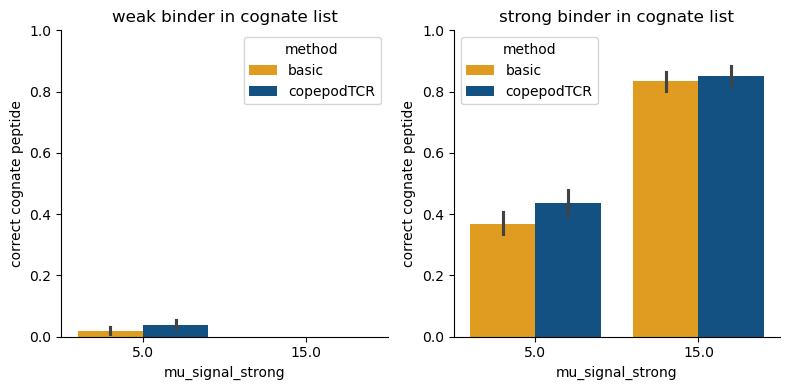

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

## selecting a subset with low signal for a weak binder (5)
subset = results_cross[(results_cross['mu_signal_weak'] == 5)]

## whether a weak binder was identified correctly
### conclusion_cognate == True => list with correct cognate peptides == (exactly equal!) list of cognate peptides predicted by the model
ax = axes[0]
sn.barplot(subset, x = 'mu_signal_strong', y = 'conclusion_cognate_weak',
        hue = 'method', palette = [color_basic, color_copepodTCR], ax = ax)
ax.set_title(f'weak binder in cognate list')
ax.set_ylabel('correct cognate peptide')
ax.set_ylim([0, 1])

## whether a strong binder was identified correctly
### conclusion_cognate == True => list with correct cognate peptides == (exactly equal!) list of cognate peptides predicted by the model
ax = axes[1]
sn.barplot(subset, x = 'mu_signal_strong', y = 'conclusion_cognate_strong',
        hue = 'method', palette = [color_basic, color_copepodTCR], ax = ax)
ax.set_title(f'strong binder in cognate list')
ax.set_ylabel('correct cognate peptide')
ax.set_ylim([0, 1])

plt.tight_layout()
sn.despine()